In [199]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import nltk
import requests

from collections import Counter, defaultdict
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

print("All libraries imported successfully!")

All libraries imported successfully!


In [200]:
import requests

url = "https://www.gutenberg.org/cache/epub/11/pg11.txt"

response = requests.get(url)
text_data = response.text

print("Dataset downloaded successfully!")
print("Total characters:", len(text_data))
print(text_data[:500])

Dataset downloaded successfully!
Total characters: 167712
The Project Gutenberg eBook of Alice's Adventures in Wonderland
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
befor


In [201]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [202]:
# Convert text to lowercase
clean_text = text_data.lower()

# Remove punctuation and numbers
clean_text = re.sub(r'[^a-z\s]', '', clean_text)

# Split text into words
words = word_tokenize(clean_text)

# Remove common English stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("Text preprocessing completed!")
print("Total words:", len(filtered_words))
print("Sample words:", filtered_words[:20])

Text preprocessing completed!
Total words: 14357
Sample words: ['project', 'gutenberg', 'ebook', 'alices', 'adventures', 'wonderland', 'ebook', 'use', 'anyone', 'anywhere', 'united', 'states', 'parts', 'world', 'cost', 'almost', 'restrictions', 'whatsoever', 'may', 'copy']


In [203]:
# Create bigram and trigram combinations

bigrams = list(zip(filtered_words[:-1], filtered_words[1:]))

trigrams = list(zip(
    filtered_words[:-2],
    filtered_words[1:-1],
    filtered_words[2:]
))

# Count how frequently each combination appears
bigram_counts = Counter(bigrams)
trigram_counts = Counter(trigrams)

print("Bigram model created!")
print("Trigram model created!")

print("Total bigrams:", len(bigrams))
print("Total trigrams:", len(trigrams))

Bigram model created!
Trigram model created!
Total bigrams: 14356
Total trigrams: 14355


In [204]:
def autocomplete(prefix):
    prefix_words = prefix.lower().split()

    if len(prefix_words) >= 2:
        last_two = tuple(prefix_words[-2:])

        predictions = {
            word: count
            for (w1, w2, word), count in trigram_counts.items()
            if (w1, w2) == last_two
        }

    else:
        last_word = prefix_words[-1]

        predictions = {
            word: count
            for (w1, word), count in bigram_counts.items()
            if w1 == last_word
        }

    top_predictions = sorted(
        predictions.items(),
        key=lambda x: x[1],
        reverse=True
    )[:3]

    return [word for word, count in top_predictions]


print("Autocomplete function created successfully!")

Autocomplete function created successfully!


In [205]:
test_prefixes = [
    "alice",
    "white rabbit",
    "queen of",
    "said the",
    "mock turtle",
    "march hare",
    "little girl",
    "looked at",
    "king of",
    "went to"
]

for prefix in test_prefixes:
    print("Prefix:", prefix)
    print("Predictions:", autocomplete(prefix))
    print("-------------------------")

Prefix: alice
Predictions: ['said', 'thought', 'could']
-------------------------
Prefix: white rabbit
Predictions: ['blew', 'read', 'pink']
-------------------------
Prefix: queen of
Predictions: []
-------------------------
Prefix: said the
Predictions: []
-------------------------
Prefix: mock turtle
Predictions: ['said', 'went', 'replied']
-------------------------
Prefix: march hare
Predictions: ['said', 'hatter', 'went']
-------------------------
Prefix: little girl
Predictions: ['shell', 'said', 'serpent']
-------------------------
Prefix: looked at
Predictions: []
-------------------------
Prefix: king of
Predictions: []
-------------------------
Prefix: went to
Predictions: []
-------------------------


In [206]:
!pip install pyspellchecker

In [207]:
from spellchecker import SpellChecker

# Create spell checker
spell = SpellChecker()

# Define autocorrect function
def autocorrect(word):
    corrected_word = spell.correction(word.lower())
    return corrected_word

print("Autocorrect function created successfully!")

Autocorrect function created successfully!


In [208]:
misspelled_words = [
    " recieve", "teh", "becaus", "freind", "langauge",
    "computr", "writting", "beleive", "acheive", "definately",
    "seperate", "occured", "untill", "thier", "goverment",
    "enviroment", "studing", "developement", "knowlege", "begining"
]

for word in misspelled_words:
    word = word.strip()
    print(word, " --> ", autocorrect(word))

recieve  -->  receive
teh  -->  the
becaus  -->  because
freind  -->  friend
langauge  -->  language
computr  -->  computer
writting  -->  writing
beleive  -->  believe
acheive  -->  achieve
definately  -->  definitely
seperate  -->  separate
occured  -->  occurred
untill  -->  until
thier  -->  their
goverment  -->  government
enviroment  -->  environment
studing  -->  studying
developement  -->  development
knowlege  -->  knowledge
begining  -->  beginning


In [209]:
correct_words = [
    "receive", "the", "because", "friend", "language",
    "computer", "writing", "believe", "achieve", "definitely",
    "separate", "occurred", "until", "their", "government",
    "environment", "studying", "development", "knowledge", "beginning"
]

correct_predictions = 0

for wrong, expected in zip(misspelled_words, correct_words):
    prediction = autocorrect(wrong.strip())

    if prediction == expected:
        correct_predictions += 1

accuracy = (correct_predictions / len(correct_words)) * 100

print("Correct predictions:", correct_predictions)
print("Total test words:", len(correct_words))
print("Autocorrect Accuracy:", round(accuracy, 2), "%")

Correct predictions: 20
Total test words: 20
Autocorrect Accuracy: 100.0 %


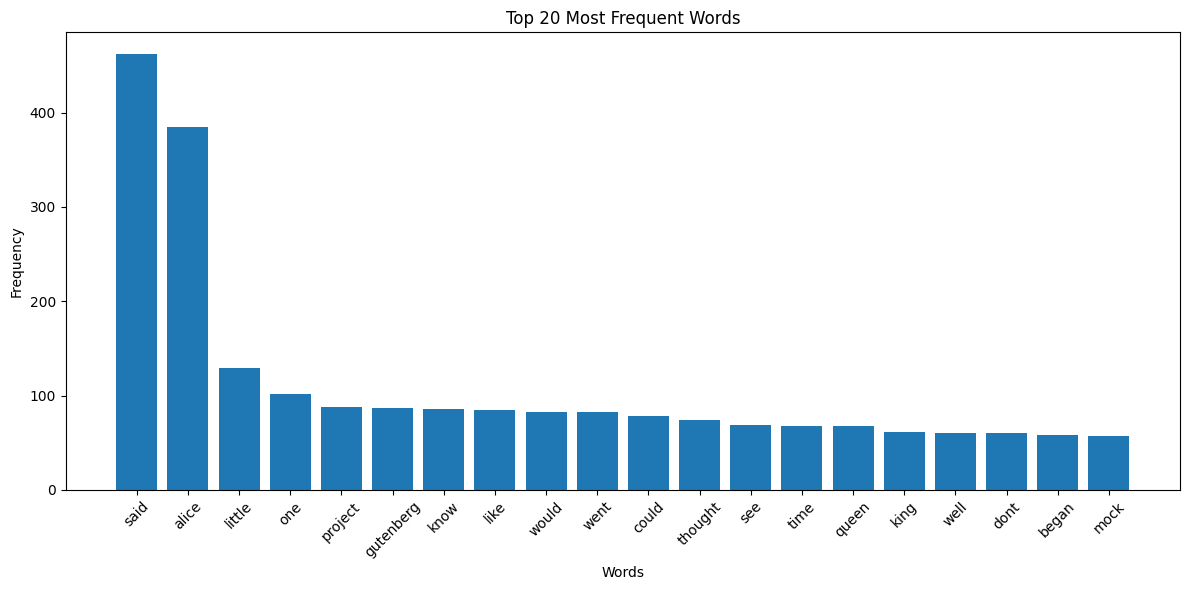

In [210]:
# Count word frequencies
word_counts = Counter(filtered_words)

# Get the 20 most common words
top_20 = word_counts.most_common(20)

words_list = [word for word, count in top_20]
counts_list = [count for word, count in top_20]

# Create bar chart
plt.figure(figsize=(12, 6))
plt.bar(words_list, counts_list)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [211]:
hits = 0
total = 100

for i in range(3, min(len(filtered_words), 103)):
    prefix = " ".join(filtered_words[i-2:i])
    actual_word = filtered_words[i]

    predictions = autocomplete(prefix)

    if actual_word in predictions:
        hits += 1

precision = hits / (total * 3) * 100
recall = hits / total * 100

print("Correct top-3 predictions:", hits)
print("Precision@3:", round(precision, 2), "%")
print("Recall@3:", round(recall, 2), "%")

Correct top-3 predictions: 98
Precision@3: 32.67 %
Recall@3: 98.0 %


In [212]:
# Test words
test_words = misspelled_words + correct_words

# 1 = misspelled, 0 = correctly spelled
actual_labels = [1] * 20 + [0] * 20

# Predict whether each word is misspelled
predicted_labels = [
    1 if word.strip() in spell.unknown([word.strip()]) else 0
    for word in test_words
]

# Calculate TP, FP and FN
TP = sum(a == 1 and p == 1 for a, p in zip(actual_labels, predicted_labels))
FP = sum(a == 0 and p == 1 for a, p in zip(actual_labels, predicted_labels))
FN = sum(a == 1 and p == 0 for a, p in zip(actual_labels, predicted_labels))

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0

print("True Positives:", TP)
print("False Positives:", FP)
print("False Negatives:", FN)
print("Autocorrect Precision:", round(precision * 100, 2), "%")
print("Autocorrect Recall:", round(recall * 100, 2), "%")

True Positives: 20
False Positives: 0
False Negatives: 0
Autocorrect Precision: 100.0 %
Autocorrect Recall: 100.0 %


In [213]:
def bigram_prediction(word):
    results = {
        w2: count
        for (w1, w2), count in bigram_counts.items()
        if w1 == word.lower()
    }
    return sorted(results.items(), key=lambda x: x[1], reverse=True)[:3]


def trigram_prediction(words):
    words = words.lower().split()
    last_two = tuple(words[-2:])

    results = {
        w3: count
        for (w1, w2, w3), count in trigram_counts.items()
        if (w1, w2) == last_two
    }
    return sorted(results.items(), key=lambda x: x[1], reverse=True)[:3]


print("Bigram predictions:", bigram_prediction("alice"))
print("Trigram predictions:", trigram_prediction("white rabbit"))

Bigram predictions: [('said', 17), ('thought', 13), ('could', 11)]
Trigram predictions: [('blew', 2), ('read', 2), ('pink', 1)]


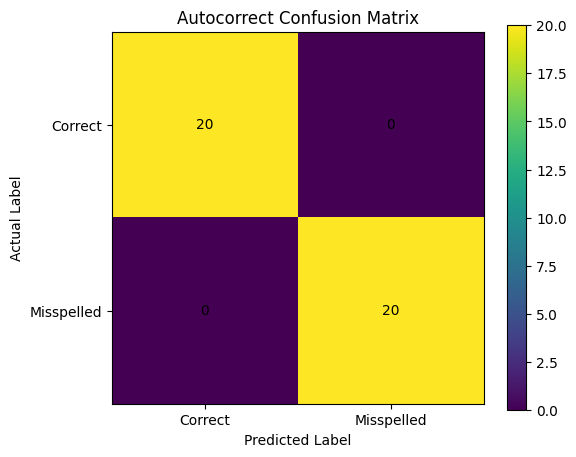

In [214]:
import matplotlib.pyplot as plt

TN = sum(a == 0 and p == 0 for a, p in zip(actual_labels, predicted_labels))

confusion = [
    [TN, FP],
    [FN, TP]
]

plt.figure(figsize=(6, 5))
plt.imshow(confusion)

plt.title("Autocorrect Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Correct", "Misspelled"])
plt.yticks([0, 1], ["Correct", "Misspelled"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, confusion[i][j], ha="center", va="center")

plt.colorbar()
plt.show()

In [215]:
comparison = pd.DataFrame({
    "Original Word": [word.strip() for word in misspelled_words],
    "Corrected Word": [
        autocorrect(word.strip()) for word in misspelled_words
    ],
    "Expected Word": correct_words
})

print(comparison.to_string(index=False))

Original Word Corrected Word Expected Word
      recieve        receive       receive
          teh            the           the
       becaus        because       because
       freind         friend        friend
     langauge       language      language
      computr       computer      computer
     writting        writing       writing
      beleive        believe       believe
      acheive        achieve       achieve
   definately     definitely    definitely
     seperate       separate      separate
      occured       occurred      occurred
       untill          until         until
        thier          their         their
    goverment     government    government
   enviroment    environment   environment
      studing       studying      studying
 developement    development   development
     knowlege      knowledge     knowledge
     begining      beginning     beginning


In [216]:
comparison.to_csv("Autocorrect_Results.csv", index=False)

print("CSV file saved successfully!")

CSV file saved successfully!


In [217]:
from google.colab import files

files.download("Autocorrect_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task 5: Autocomplete and Autocorrect Data Analytics

## Project Overview
This project develops a basic autocomplete and autocorrect system using Natural Language Processing (NLP) techniques.

## Dataset
- Source: Project Gutenberg
- Book: Alice's Adventures in Wonderland
- Dataset size: 167,712 characters

## Technologies Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- NLTK
- PySpellChecker

## Project Implementation
1. Downloaded a text dataset.
2. Performed text preprocessing.
3. Created bigram and trigram models.
4. Implemented autocomplete predictions.
5. Tested autocomplete with 10 prefixes.
6. Implemented autocorrect using PySpellChecker.
7. Tested 20 misspelled words.
8. Calculated accuracy, precision and recall.
9. Visualized frequent words and the confusion matrix.
10. Compared bigram and trigram predictions.

## Results
The project demonstrates basic autocomplete and autocorrect functionality using NLP and frequency-based prediction techniques.

## Conclusion
This project provides practical experience in text preprocessing, word prediction, spelling correction and NLP evaluation.